In [ ]:
# Download the 6GB dataset directly from Zenodo
!wget -O s1s2_landslide_reference_data.zip \
https://zenodo.org/records/17007637/files/s1s2_landslide_reference_data.zip?download=1

--2026-06-15 08:25:01--  https://zenodo.org/records/17007637/files/s1s2_landslide_reference_data.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.153.219, 188.185.43.153, 137.138.52.235, ...
Connecting to zenodo.org (zenodo.org)|137.138.153.219|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5991736566 (5.6G) [application/octet-stream]
Saving to: ‘s1s2_landslide_reference_data.zip’

ata.zip              11%[=>                  ] 683.07M  2.38MB/s    eta 29m 45s^C


In [ ]:
!unzip s1s2_landslide_reference_data.zip

Archive:  s1s2_landslide_reference_data.zip
   creating: s1s2_landslide_reference_data/
   creating: s1s2_landslide_reference_data/original_scenes/
   creating: s1s2_landslide_reference_data/original_scenes/BR0001/
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__CDEM__None__DEM.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__CDEM__None__SLOPE.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__files_meta.csv  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__None__None__MASK.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__S1SLC__2018-12-29_2019-01-10__DES_COHVV.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__S1SLC__2018-12-29__DES_ALPHA.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__S1SLC__2018-12-29__DES_ANISOTROPY.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/B

In [ ]:
import h5py

path = "/content/s1s2_landslide_reference_data/reference_data/train_n3_s1s2.h5"

with h5py.File(path, "r") as f:
    print("Keys:", list(f.keys()))

    for k in f.keys():
        print(k, f[k].shape, f[k].dtype)

Keys: ['None_DEM', 'None_MASK', 'None_SLOPE', 'POST1_ALPHA', 'POST1_ANISOTROPY', 'POST1_B02', 'POST1_B03', 'POST1_B04', 'POST1_B05', 'POST1_B06', 'POST1_B07', 'POST1_B08', 'POST1_B11', 'POST1_B12', 'POST1_B8A', 'POST1_COHVV', 'POST1_ENTROPY', 'POST1_NDVI', 'POST1_gVH', 'POST1_gVV', 'POST2_ALPHA', 'POST2_ANISOTROPY', 'POST2_COHVV', 'POST2_ENTROPY', 'POST2_gVH', 'POST2_gVV', 'POST3_ALPHA', 'POST3_ANISOTROPY', 'POST3_COHVV', 'POST3_ENTROPY', 'POST3_gVH', 'POST3_gVV', 'PRE1_ALPHA', 'PRE1_ANISOTROPY', 'PRE1_B02', 'PRE1_B03', 'PRE1_B04', 'PRE1_B05', 'PRE1_B06', 'PRE1_B07', 'PRE1_B08', 'PRE1_B11', 'PRE1_B12', 'PRE1_B8A', 'PRE1_COHVV', 'PRE1_ENTROPY', 'PRE1_NDVI', 'PRE1_gVH', 'PRE1_gVV', 'PRE2_ALPHA', 'PRE2_ANISOTROPY', 'PRE2_COHVV', 'PRE2_ENTROPY', 'PRE2_gVH', 'PRE2_gVV', 'PRE3_ALPHA', 'PRE3_ANISOTROPY', 'PRE3_ENTROPY', 'PRE3_gVH', 'PRE3_gVV']
None_DEM (355, 1, 128, 128) float32
None_MASK (355, 1, 128, 128) float32
None_SLOPE (355, 1, 128, 128) float32
POST1_ALPHA (355, 1, 128, 128) float32
P

In [ ]:
!pip install -q transformers timm evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.7 MB/s eta 0:00:00


imports

In [ ]:
import time
import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    jaccard_score,
    confusion_matrix
)

Cell 2: Count Trainable Parameters

In [ ]:
from transformers import SegformerForSemanticSegmentation

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b4-finetuned-ade-512-512",
    num_labels=2,
    ignore_mismatched_sizes=True
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/6.89k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


pytorch_model.bin:   0%|          | 0.00/257M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/257M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/930 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b4-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 768, 1, 1]) vs model:torch.Size([2, 768, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [ ]:
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable Parameters: {trainable_params/1e6:.2f} M")

Trainable Parameters: 63.99 M


Dataloader

In [ ]:
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from transformers import SegformerForSemanticSegmentation

from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import jaccard_score

from tqdm import tqdm

In [ ]:
class LandslideDataset(Dataset):

    def __init__(self, h5_path):

        self.h5_path = h5_path

        with h5py.File(h5_path, "r") as f:
            self.length = f["None_MASK"].shape[0]

    def __len__(self):
        return self.length

    def __getitem__(self, idx):

        with h5py.File(self.h5_path, "r") as f:

            red = f["POST1_B04"][idx,0]
            green = f["POST1_B03"][idx,0]
            blue = f["POST1_B02"][idx,0]

            mask = f["None_MASK"][idx,0]

        image = np.stack(
            [red, green, blue],
            axis=0
        )

        image = image.astype(np.float32)

        image = (
            image - image.min()
        ) / (
            image.max() - image.min() + 1e-8
        )

        mask = (mask > 0).astype(np.int64)

        return (
            torch.tensor(image),
            torch.tensor(mask)
        )

In [ ]:
train_path = "/content/s1s2_landslide_reference_data/reference_data/train_n3_s1s2.h5"

val_path = "/content/s1s2_landslide_reference_data/reference_data/val_n3_s1s2.h5"

test_path = "/content/s1s2_landslide_reference_data/reference_data/testind_n3_s1s2.h5"

In [ ]:
train_dataset = LandslideDataset(train_path)
val_dataset = LandslideDataset(val_path)
test_dataset = LandslideDataset(test_path)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

In [ ]:
model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b4-finetuned-ade-512-512",
    num_labels=2,
    ignore_mismatched_sizes=True
)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/930 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b4-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 768, 1, 1]) vs model:torch.Size([2, 768, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)

SegformerForSemanticSegmentation(
  (segformer): SegformerModel(
    (stages): ModuleList(
      (0): SegformerStage(
        (patch_embeddings): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(3, 64, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
          (layer_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        )
        (blocks): ModuleList(
          (0): SegformerLayer(
            (layernorm_before): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
            (attention): SegformerAttention(
              (q_proj): Linear(in_features=64, out_features=64, bias=True)
              (k_proj): Linear(in_features=64, out_features=64, bias=True)
              (v_proj): Linear(in_features=64, out_features=64, bias=True)
              (o_proj): Linear(in_features=64, out_features=64, bias=True)
              (sequence_reduction): SegformerSequenceReduction(
                (sequence_reduction): Conv2d(64, 64, kernel_size=(8, 8), stride=(8, 8))
        

In [ ]:
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(
        [1.0,3.4]
    ).to(device)
)

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=0.01
)

In [ ]:
def evaluate(model, loader):

    model.eval()

    all_preds = []
    all_masks = []

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(
                pixel_values=images
            )

            logits = outputs.logits

            logits = F.interpolate(
                logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            preds = torch.argmax(
                logits,
                dim=1
            )

            all_preds.extend(
                preds.cpu().numpy().flatten()
            )

            all_masks.extend(
                masks.cpu().numpy().flatten()
            )

    precision = precision_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    recall = recall_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    f1 = f1_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    iou = jaccard_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    return precision, recall, f1, iou

Start time

In [ ]:
training_start = time.time()

Training Loop

In [ ]:
best_iou = 0

for epoch in range(25):

    model.train()

    running_loss = 0

    loop = tqdm(train_loader)

    for images, masks in loop:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(
            pixel_values=images
        )

        logits = outputs.logits

        logits = F.interpolate(
            logits,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        loss = criterion(
            logits,
            masks
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        loop.set_description(
            f"Epoch {epoch+1}"
        )

        loop.set_postfix(
            loss=loss.item()
        )

    precision, recall, f1, iou = evaluate(
        model,
        val_loader
    )

    print(
        f"\nEpoch {epoch+1}"
    )

    print(
        f"Precision={precision:.4f}"
    )

    print(
        f"Recall={recall:.4f}"
    )

    print(
        f"F1={f1:.4f}"
    )

    print(
        f"IoU={iou:.4f}"
    )

    if iou > best_iou:

        best_iou = iou

        torch.save(
            model.state_dict(),
            "best_segformer_b4.pth"
        )

        print(
            "Best model saved"
        )

Epoch 1: 100%|██████████| 23/23 [00:08<00:00,  2.71it/s, loss=0.17]



Epoch 1
Precision=0.7923
Recall=0.8908
F1=0.8387
IoU=0.7222
Best model saved


Epoch 2: 100%|██████████| 23/23 [00:07<00:00,  2.97it/s, loss=0.157]



Epoch 2
Precision=0.7829
Recall=0.9320
F1=0.8510
IoU=0.7406
Best model saved


Epoch 3: 100%|██████████| 23/23 [00:08<00:00,  2.63it/s, loss=0.188]


...


Epoch 23
Precision=0.9227
Recall=0.9691
F1=0.9453
IoU=0.8963
Best model saved


Epoch 24: 100%|██████████| 23/23 [00:07<00:00,  2.94it/s, loss=0.0318]



Epoch 24
Precision=0.9096
Recall=0.9732
F1=0.9403
IoU=0.8874


Epoch 25: 100%|██████████| 23/23 [00:07<00:00,  2.91it/s, loss=0.0397]



Epoch 25
Precision=0.9024
Recall=0.9797
F1=0.9395
IoU=0.8859


In [ ]:
training_end = time.time()

training_time = (
    training_end -
    training_start
)

print(
    f"Training Time: "
    f"{training_time/60:.2f} minutes"
)

Training Time: 6.67 minutes


Cell 6: Evaluation Function

In [ ]:
import time
import numpy as np
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    jaccard_score,
    confusion_matrix
)

def evaluate_model(model, loader, device):

    model.eval()

    y_true = []
    y_pred = []

    total_time = 0
    total_images = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)

            start = time.time()

            outputs = model(images)

            if torch.cuda.is_available():
                torch.cuda.synchronize()

            total_time += time.time() - start

            logits = outputs.logits

            # Upsample 32x32 → 128x128
            logits = F.interpolate(
                logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            preds = torch.argmax(
                logits,
                dim=1
            )

            preds = preds.cpu().numpy()
            masks = masks.numpy()

            y_pred.extend(
                preds.flatten()
            )

            y_true.extend(
                masks.flatten()
            )

            total_images += images.size(0)

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="binary",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="binary",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="binary",
        zero_division=0
    )

    iou = jaccard_score(
        y_true,
        y_pred,
        average="binary",
        zero_division=0
    )

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    inference_time = (
        total_time /
        total_images
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou,
        "ConfusionMatrix": cm,
        "InferenceTime": inference_time
    }

Cell 7: Evaluate Validation Set

In [ ]:
results = evaluate_model(
    model,
    val_loader,
    device
)

Print results

In [ ]:
print("\nValidation Results")

print(
    f"Accuracy : {results['Accuracy']:.4f}"
)

print(
    f"Precision: {results['Precision']:.4f}"
)

print(
    f"Recall   : {results['Recall']:.4f}"
)

print(
    f"F1       : {results['F1']:.4f}"
)

print(
    f"IoU      : {results['IoU']:.4f}"
)

print(
    f"Training Time : "
    f"{training_time/60:.2f} min"
)

print(
    f"Inference Time: "
    f"{results['InferenceTime']*1000:.2f} ms/image"
)


Validation Results
Accuracy : 0.9864
Precision: 0.9024
Recall   : 0.9797
F1       : 0.9395
IoU      : 0.8859
Training Time : 6.67 min
Inference Time: 14.58 ms/image


confusion metrics

In [ ]:
print(
    "\nConfusion Matrix:"
)

print(
    results["ConfusionMatrix"]
)


Confusion Matrix:
[[1269815   16471]
 [   3155  152351]]


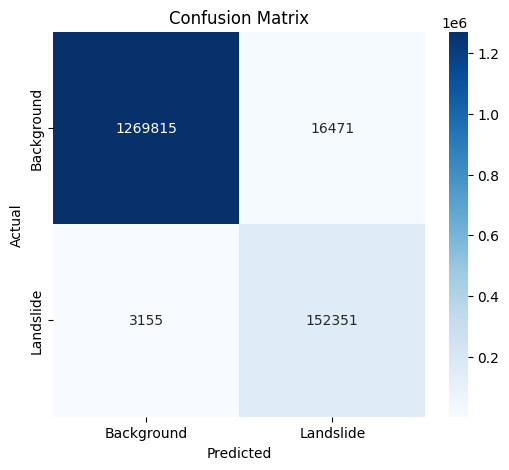

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.heatmap(
    results["ConfusionMatrix"],
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Background",
        "Landslide"
    ],
    yticklabels=[
        "Background",
        "Landslide"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

Trainable parameters

In [ ]:
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    f"Trainable Parameters: "
    f"{trainable_params/1e6:.2f} M"
)

Trainable Parameters: 63.99 M


In [ ]:
print(type(train_dataset))

<class '__main__.LandslideDataset'>


In [ ]:
print(len(train_dataset))

355
